### Phase 3: EDA

In [1]:

import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# seting visual style
# sns.set_theme(style="whitegrid")
# plt.figure(figsize=(10, 6))

In [2]:
df_clean = pd.read_parquet('../final_datasets/clean_datasets/1_data_preparation_dataset.parquet', engine='fastparquet')
df_clean.shape

(12112, 54)

In [3]:
df_clean.info()

<class 'pandas.DataFrame'>
MultiIndex: 12112 entries, (np.int64(1991), 'AX010') to (np.int64(2019), 'UNNAMED 25953')
Data columns (total 54 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   area_change           12112 non-null  float64
 1   elevation_change      12112 non-null  float64
 2   elevation_change_unc  12112 non-null  float64
 3   cenlon                12112 non-null  float64
 4   cenlat                12112 non-null  float64
 5   area_km2              12112 non-null  float64
 6   surge_type            12112 non-null  int64  
 7   zmin_m                12112 non-null  float64
 8   zmax_m                12112 non-null  float64
 9   zmed_m                12112 non-null  float64
 10  zmean_m               12112 non-null  float64
 11  slope_deg             12112 non-null  float64
 12  aspect_deg            12112 non-null  float64
 13  aspect_sec            12112 non-null  int64  
 14  lmax_m                12112 n

In [4]:
df_clean.head()

area_change  elevation_change  elevation_change_unc  \
year glacier_name                                                        
1991 AX010            568000.0            -8.689                  4.79   
1996 AX010            495000.0            -5.500                  4.79   
1999 AX010            450000.0            -2.470                  4.79   
2002 LHOTSE NUP       375000.0            -2.220                  4.79   
     NUPTSE           300000.0            -1.970                  4.79   

                      cenlon     cenlat  area_km2  surge_type     zmin_m  \
year glacier_name                                                          
1991 AX010         86.555703  27.715657  0.426034           0  4977.4860   
1996 AX010         86.555703  27.715657  0.426034           0  4977.4860   
1999 AX010         86.555703  27.715657  0.426034           0  4977.4860   
2002 LHOTSE NUP    86.890141  27.936466  2.351926           0  4963.2207   
     NUPTSE        86.861770  27.938681  2.351926           0  4973.5070   

                        zmax_m     zmed_m  ...          strd        ro  \
year glacier_name                          ...                           
1991 AX010         5326.812500  5221.8740  ...  2.314026e+07  0.003685   
1996 AX010         5326.812500  5221.8740  ...  2.301200e+07  0.003965   
1999 AX010         5326.812500  5221.8740  ...  2.367911e+07  0.004271   
2002 LHOTSE NUP    7105.239513  5261.5150  ...  1.938723e+07  0.001766   
     NUPTSE        5957.843300  5359.0513  ...  1.938723e+07  0.001766   

                         es       sro         e       u10       v10  \
year glacier_name                                                     
1991 AX010        -0.000035  0.002045 -0.001696  0.223243 -0.138062   
1996 AX010        -0.000023  0.002109 -0.001571  0.182166 -0.207591   
1999 AX010        -0.000011  0.002437 -0.001723  0.200245 -0.033395   
2002 LHOTSE NUP   -0.000061  0.000944 -0.000632  0.487552  0.008241   
     NUPTSE       -0.000061  0.000944 -0.000632  0.487552  0.008241   

                             sp        tp  actual_mass_change  
year glacier_name                                              
1991 AX010         63915.844667  0.005390          -4193900.0  
1996 AX010         63915.595917  0.005374          -2312000.0  
1999 AX010         63936.862250  0.006063           -943500.0  
2002 LHOTSE NUP    53253.895667  0.003240         -15300000.0  
     NUPTSE        53253.895667  0.003240         -36720000.0  

[5 rows x 54 columns]

In [5]:
df_map = df_clean.reset_index()


In [6]:


# calculating the exact center coordinates of the dataset
center_lat = df_map['cenlat'].mean()
center_lon = df_map['cenlon'].mean()

# defining a custom color sequence: Black/Purple (extreme loss) -> Red (loss) -> Green (gain)
custom_color_scale = [
    [0.0, "black"],   # Maximum mass loss
    [0.25, "purple"], # Severe mass loss
    [0.48, "red"],    # Moderate mass loss
    [0.5, "pink"],# Zero change
    [1.0, "green"]    # Mass gain
]

# interactive OpenStreetMap scatter plot
fig = px.scatter_map(
    df_map, 
    lat="cenlat", 
    lon="cenlon", 
    color="actual_mass_change",
    size="area_km2",
    hover_name="glacier_name",          
    hover_data=["year", "actual_mass_change"], 
    color_continuous_scale=custom_color_scale,
    size_max=8,                         
    zoom=5,                           
    center={"lat": center_lat, "lon": center_lon}, 
    map_style="open-street-map",        
    title="OpenStreetMap: Glacier Mass Change "
)


fig.update_layout(margin={"r":0,"t":40,"l":0,"b":0})

fig.write_html('../plots/eda/glacier_map.html')
fig.show()

Red and black points cluster heavily in lower valleys, pinpointing regions experiencing severe ablation. This visual confirms that mass loss is not just a statistical trend, but a localized geographic phenomenon heavily dependent on proximity to warmer microclimates.

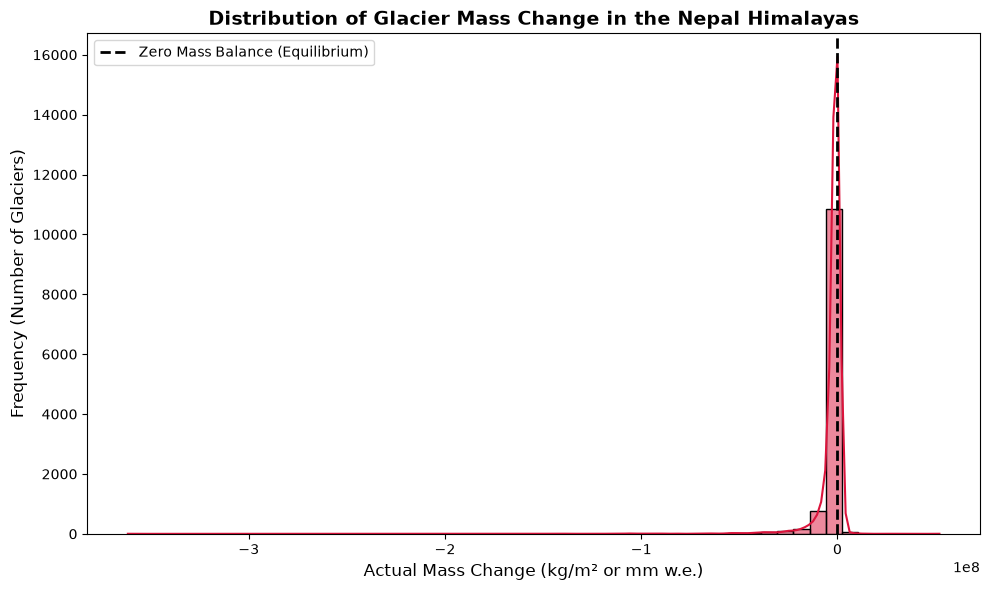

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['actual_mass_change'], bins=50, kde=True, color='crimson')
plt.axvline(0, color='black', linestyle='--', linewidth=2, label='Zero Mass Balance (Equilibrium)')
plt.title('Distribution of Glacier Mass Change in the Nepal Himalayas', fontsize=14, fontweight='bold')
plt.xlabel('Actual Mass Change (kg/m² or mm w.e.)', fontsize=12)
plt.ylabel('Frequency (Number of Glaciers)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('../plots/eda/target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


The large volume of data points falling to the left of the zero-line (black dashed line) indicates severe and widespread glacier ablation (mass loss). The long tail reaching into negative values confirms that the Nepal Himalayas are predominantly undergoing a phase of mass degradation. Because of this significant skew, converting this continuous variable into a binary class (Loss vs. Gain) is a scientifically sound approach to prevent regression models from overfitting to extreme melting outliers. And, shows the class imbalance.

Tempeature Vs Mass Change Plot

<Figure size 800x800 with 0 Axes>

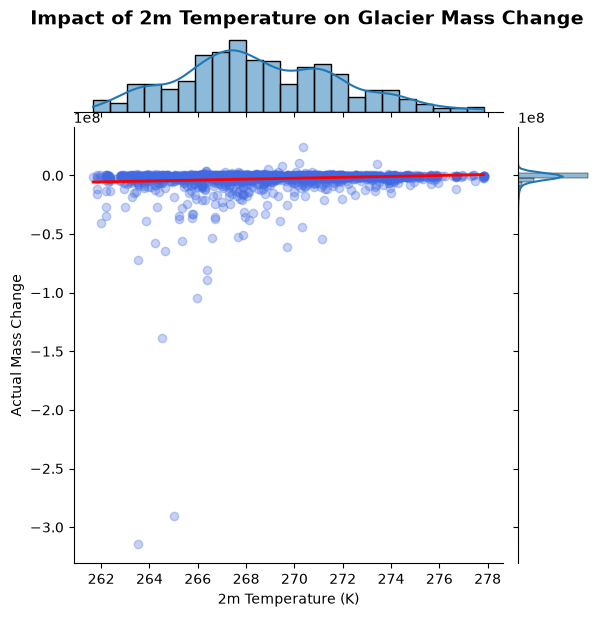

In [8]:
plt.figure(figsize=(8, 8))
# 
sns.jointplot(
    data=df_clean.sample(2000, random_state=42), 
    x='t2m', 
    y='actual_mass_change', 
    kind='reg', 
    scatter_kws={'alpha':0.3, 'color':'royalblue'}, 
    line_kws={'color':'red', 'linewidth':2}
)
plt.suptitle('Impact of 2m Temperature on Glacier Mass Change', y=1.02, fontsize=14, fontweight='bold')
plt.xlabel('2m Temperature (K)')
plt.ylabel('Actual Mass Change')
plt.savefig('../plots/eda/temp_vs_mass_change.png', dpi=300, bbox_inches='tight')
plt.show()


The bivariate regression plot clearly demonstrates an inverse relationship between the 2m Temperature (t2m) and Actual Mass Change. As temperatures rise, there is a downward trend in mass balance (indicated by the red regression line).The high variance at higher temperatures highlights the complexity of local microclimates, which nonlinear machine learning models (like XGBoost) can capture significantly better than simple linear models.

<Figure size 800x800 with 0 Axes>

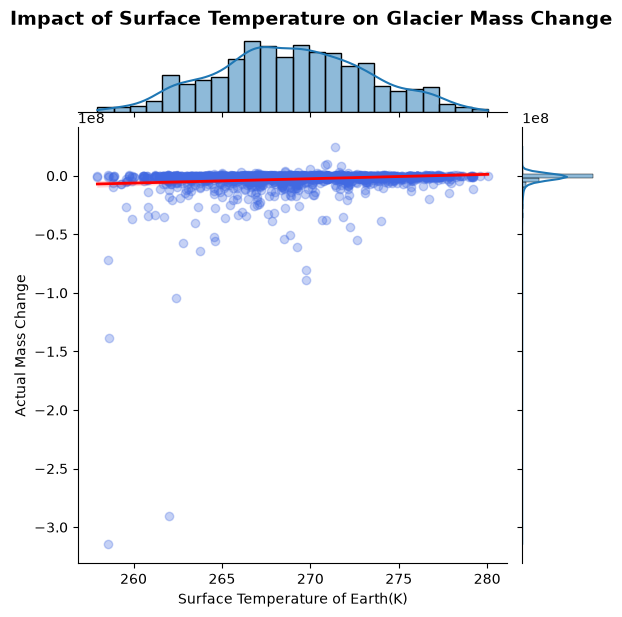

In [9]:
plt.figure(figsize=(8, 8))
# 
sns.jointplot(
    data=df_clean.sample(2000, random_state=42), 
    x='skt', 
    y='actual_mass_change', 
    kind='reg', 
    scatter_kws={'alpha':0.3, 'color':'royalblue'}, 
    line_kws={'color':'red', 'linewidth':2}
)
plt.suptitle('Impact of Surface Temperature on Glacier Mass Change', y=1.02, fontsize=14, fontweight='bold')
plt.xlabel('Surface Temperature of Earth(K)')
plt.ylabel('Actual Mass Change')
plt.savefig('../plots/eda/surface_temp_vs_mass_change.png', dpi=300, bbox_inches='tight')
plt.show()


C:\Users\shres\AppData\Local\Temp\ipykernel_7348\3337835745.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


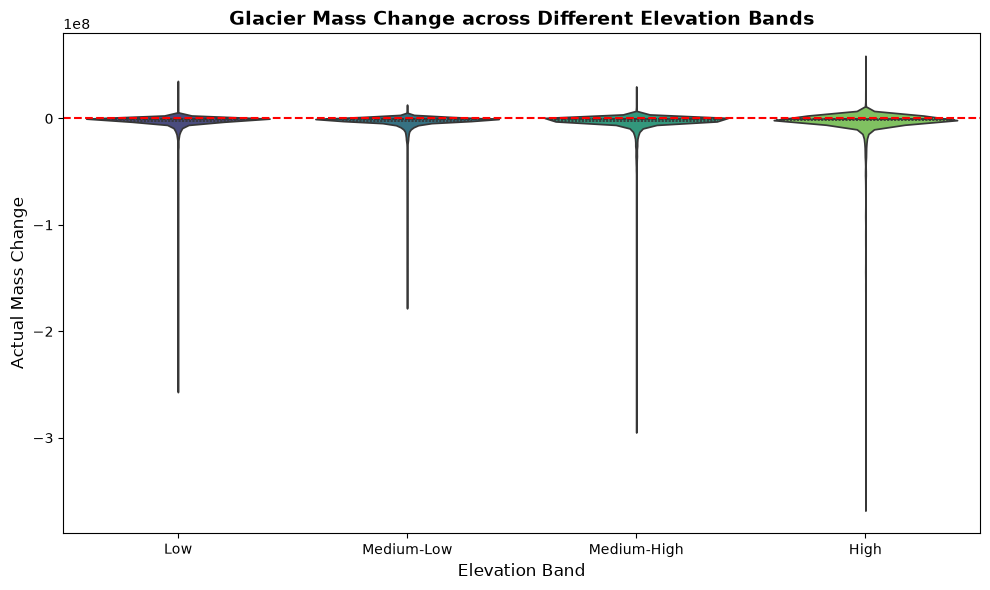

In [10]:
plt.figure(figsize=(10, 6))
# creating elevation bins for a cleaner plot
df_clean['elevation_band'] = pd.qcut(df_clean['zmed_m'], q=4, labels=['Low', 'Medium-Low', 'Medium-High', 'High'])

sns.violinplot(
    data=df_clean, 
    x='elevation_band', 
    y='actual_mass_change', 
    palette='viridis', 
    inner='quartile'
)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('Glacier Mass Change across Different Elevation Bands', fontsize=14, fontweight='bold')
plt.xlabel('Elevation Band', fontsize=12)
plt.ylabel('Actual Mass Change', fontsize=12)
plt.tight_layout()
plt.savefig('../plots/eda/elevation_vs_mass_change.png', dpi=300, bbox_inches='tight')
plt.show()



This violin plot segments glaciers into four quantiles based on median elevation (Low to High). It reveals that lower elevation glaciers experience the most extreme mass loss (widest and deepest lower tails), as they are more directly exposed to atmospheric warming and boundary layer heat fluxes. Conversely, 'High' elevation glaciers cluster much closer to the equilibrium line (red dashed line) and exhibit occasional mass gain, confirming that higher altitudes still retain some insulative resilience against climate change.

Acutal Mass Balance Vs Years

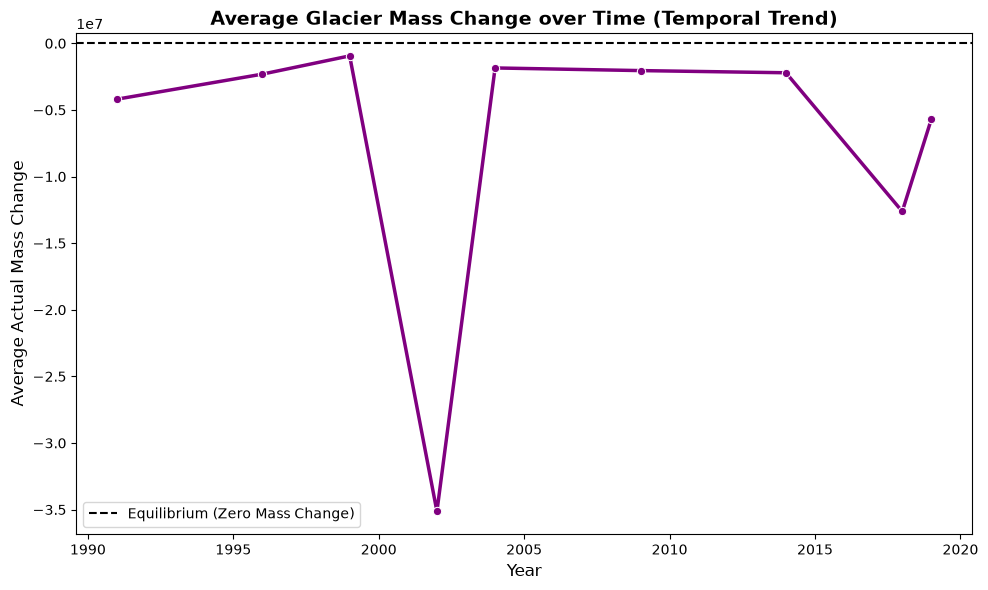

In [11]:
plt.figure(figsize=(10, 6))
# grouping by year to find the average mass change over time
yearly_mass = df_clean.groupby('year')['actual_mass_change'].mean().reset_index()

sns.lineplot(data=yearly_mass, x='year', y='actual_mass_change', marker='o', color='purple', linewidth=2.5)
plt.axhline(0, color='black', linestyle='--', linewidth=1.5, label='Equilibrium (Zero Mass Change)')

plt.title('Average Glacier Mass Change over Time (Temporal Trend)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Average Actual Mass Change', fontsize=12)
plt.legend()
plt.tight_layout()

# saving the plot
plt.savefig('../plots/eda/mass_change_vs_year.png', dpi=300, bbox_inches='tight')
plt.show()



This temporal line plot visually reinforces the continuous, multi-decadal state of ablation (mass loss) occurring across the Nepal Himalayas. Crucially, the average actual mass change remains entirely below the equilibrium line (zero mass change) from 1991 to 2019, confirming that these glaciers are in a sustained state of retreat.

The plot reveals a highly anomalous and catastrophic drop in mass balance around the year 2002, representing a period of extreme glacial melt—likely driven by an intense localized warming event or a significant disruption in monsoonal precipitation. While the average mass loss stabilized slightly in the subsequent decade, a secondary downward trend becomes evident approaching 2018. This visual evidence of accelerating volatility and continuous melting strongly justifies the application of predictive machine learning models to forecast future cryospheric hazards and downstream water availability.


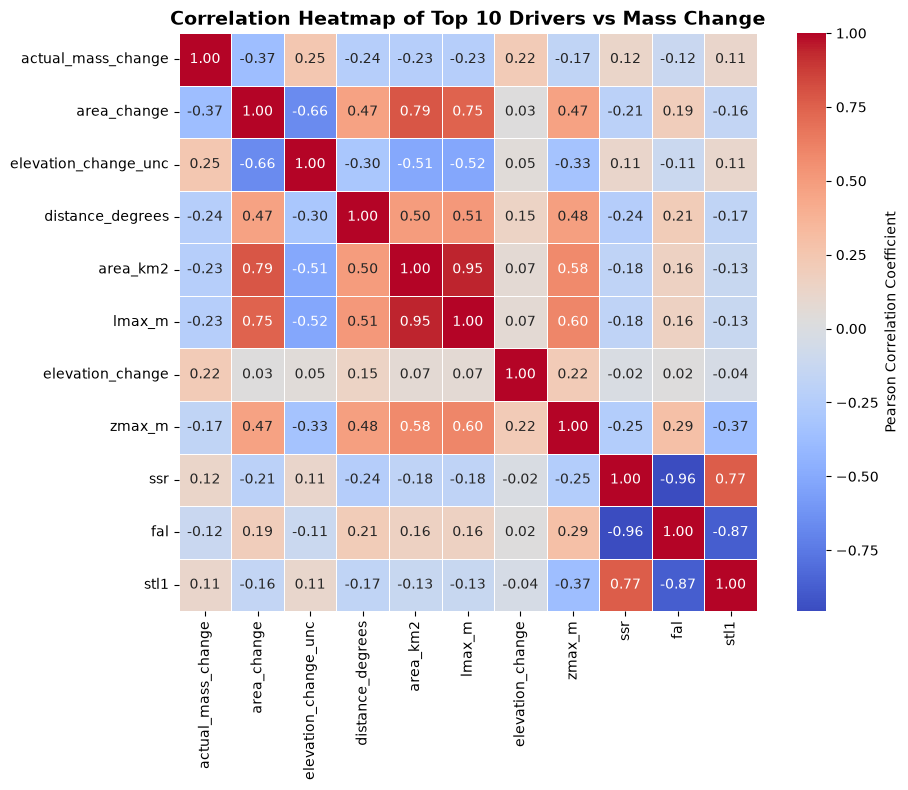

In [12]:
plt.figure(figsize=(10, 8))

# finding the absolute correlation of all numeric features with 'actual_mass_change'
numeric_df = df_clean.select_dtypes(include=['float64', 'int64'])
correlations = numeric_df.corr()['actual_mass_change'].abs().sort_values(ascending=False)

# selecting the top 10 most correlated features (including the target itself)
top_10_features = correlations.head(11).index
top_10_corr_matrix = numeric_df[top_10_features].corr()

sns.heatmap(
    top_10_corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    cbar_kws={'label': 'Pearson Correlation Coefficient'},
    square=True,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Top 10 Drivers vs Mass Change', fontsize=14, fontweight='bold')
plt.tight_layout()

plt.savefig('../plots/eda/top_10_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


This correlation heatmap isolates the top ten variables exhibiting the strongest linear relationship with actual mass change. We can observe high inter-variable collinearity among several meteorological parameters (e.g., various subsurface temperature layers like `stl1`, `stl2` and surface thermal radiation `strd`). The presence of this strong multicollinearity validates our methodological decision to apply Principal Component Analysis (PCA) and aggressive feature selection in the engineering pipeline. Addressing this collinearity ensures that our downstream machine learning models do not suffer from inflated variance or biased feature importance scoring.

Temperature Vs Snowfall, colore by mass change (Climatological Plot)

This climatological regime scatter plot elegantly illustrates the fundamental physical equation of glacier mass balance: the competition between accumulation (snowfall) and ablation (temperature-driven melting). The clustering of deep red points (severe mass loss) in the lower-right quadrant confirms that glaciers experiencing warmer 2m temperatures and lower relative snowfall suffer the highest degradation. Conversely, the cooler, higher snowfall regimes (upper-left) exhibit lighter colors, indicating stability or slight mass gain. This physical consistency in the dataset provides immense confidence in the ERA5 meteorological variables before feeding them into our machine learning models.

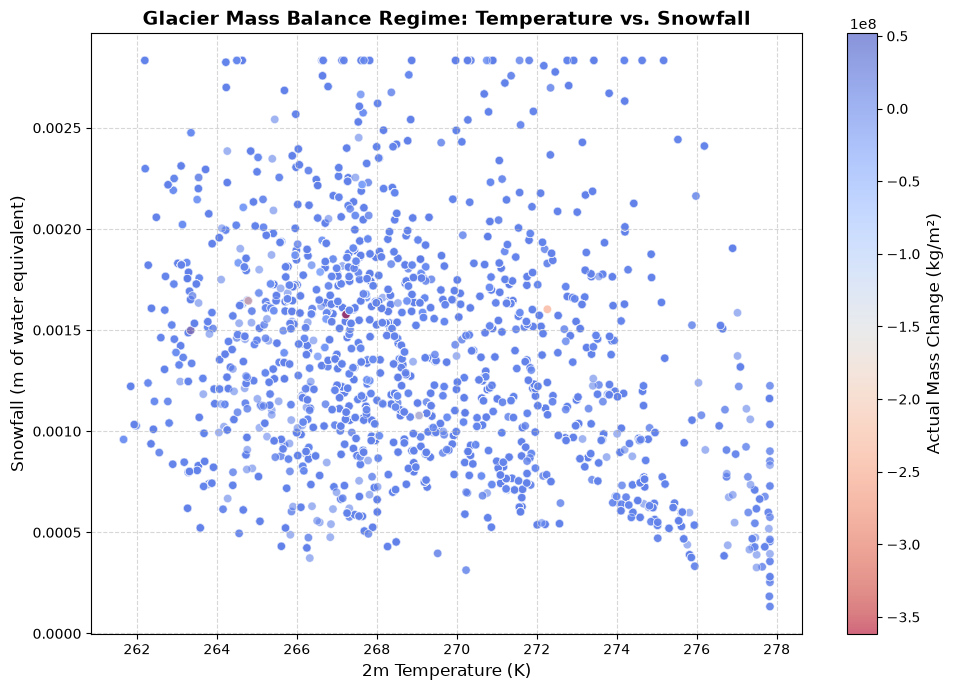

In [13]:
plt.figure(figsize=(10, 7))

# X-axis is Temperature, Y-axis is Snowfall, 
# color of the dot represents the actual mass change.
scatter = plt.scatter(
    df_clean['t2m'], 
    df_clean['sf'], 
    c=df_clean['actual_mass_change'], 
    cmap='coolwarm_r', # Red for mass loss (hot), Blue for mass gain (cold)
    alpha=0.6,
    edgecolors='w',
    linewidth=0.5
)

# adding a colorbar to explain the colors
cbar = plt.colorbar(scatter)
cbar.set_label('Actual Mass Change (kg/m²)', fontsize=12)

plt.title('Glacier Mass Balance Regime: Temperature vs. Snowfall', fontsize=14, fontweight='bold')
plt.xlabel('2m Temperature (K)', fontsize=12)
plt.ylabel('Snowfall (m of water equivalent)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()


plt.savefig('../plots/eda/temp_vs_snowfall_regime.png', dpi=300, bbox_inches='tight')
plt.show()
